11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training data shape: (10000, 28, 28, 1)
Epoch 1/50 | Generator Loss: 0.7067 | Discriminator Loss: 0.8976
Epoch 2/50 | Generator Loss: 0.7848 | Discriminator Loss: 0.6912
Epoch 3/50 | Generator Loss: 0.5812 | Discriminator Loss: 0.8706
Epoch 4/50 | Generator Loss: 1.1407 | Discriminator Loss: 0.5850
Epoch 5/50 | Generator Loss: 1.1306 | Discriminator Loss: 0.7081
Epoch 6/50 | Generator Loss: 0.9469 | Discriminator Loss: 0.8032
Epoch 7/50 | Generator Loss: 1.0009 | Discriminator Loss: 1.0504
Epoch 8/50 | Generator Loss: 0.9582 | Discriminator Loss: 0.9603
Epoch 9/50 | Generator Loss: 1.1994 | Discriminator Loss: 0.7010
Epoch 10/50 | Generator Loss: 0.8633 | Discriminator Loss: 1.0552
Epoch 11/50 | Generator Loss: 1.2222 | Discriminator Loss: 0.7394
Epoch 12/50 | Generator Loss: 0.9305 | Discriminator Loss: 0.9436
Epoch 13/50 | Generator Loss: 1.0076 | Discriminator Loss: 0.9837
Epoch 14/50 | Generator Loss: 1

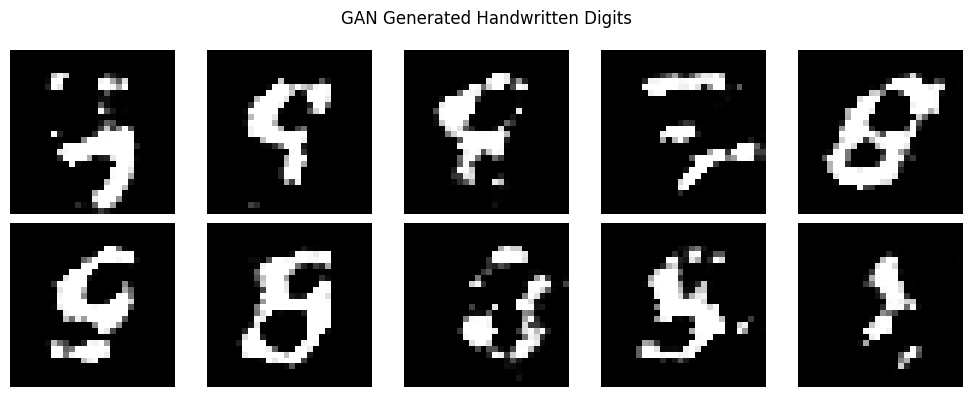

Image generation completed!


In [5]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# 1. Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize images to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = x_train[..., np.newaxis]

# Use a subset to reduce training workload
x_train = x_train[:10000]

print("Dataset loaded successfully!")
print("Training data shape:", x_train.shape)

# 2. Build Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(
        64, 4, strides=2, padding="same"
    ),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Conv2DTranspose(
        1, 4, strides=2, padding="same",
        activation="tanh"
    )
], name="generator")

# 3. Build Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(
        64, 4, strides=2, padding="same"
    ),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
], name="discriminator")

# 4. Define losses and optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
d_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

# 5. Define GAN training step
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal((batch_size, 100))

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        # Generator tries to fool the discriminator
        gen_loss = cross_entropy(
            tf.ones_like(fake_output), fake_output
        )

        # Discriminator learns real versus fake
        real_loss = cross_entropy(
            tf.ones_like(real_output), real_output
        )
        fake_loss = cross_entropy(
            tf.zeros_like(fake_output), fake_output
        )
        disc_loss = real_loss + fake_loss

    # Calculate gradients
    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    # Update both networks
    g_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )
    d_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss

# 6. Prepare dataset
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(128)

# 7. Train GAN
epochs = 50

for epoch in range(epochs):
    gen_loss_value = 0.0
    disc_loss_value = 0.0

    for batch in dataset:
        gen_loss, disc_loss = train_step(batch)
        gen_loss_value = float(gen_loss.numpy())
        disc_loss_value = float(disc_loss.numpy())

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Generator Loss: {gen_loss_value:.4f} | "
        f"Discriminator Loss: {disc_loss_value:.4f}"
    )

print("GAN training completed!")

# 8. Generate 10 handwritten digit images
noise = tf.random.normal((10, 100))
generated_images = generator(noise, training=False)

# 9. Display generated images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    image = generated_images[i, :, :, 0]
    image = (image + 1.0) / 2.0
    plt.imshow(image, cmap="gray")
    plt.axis("off")

plt.suptitle("GAN Generated Handwritten Digits")
plt.tight_layout()
plt.show()

print("Image generation completed!")


In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [7]:
print("Generator exists:", "generator" in globals())
print("Training function exists:", "train_step" in globals())

Generator exists: True
Training function exists: True


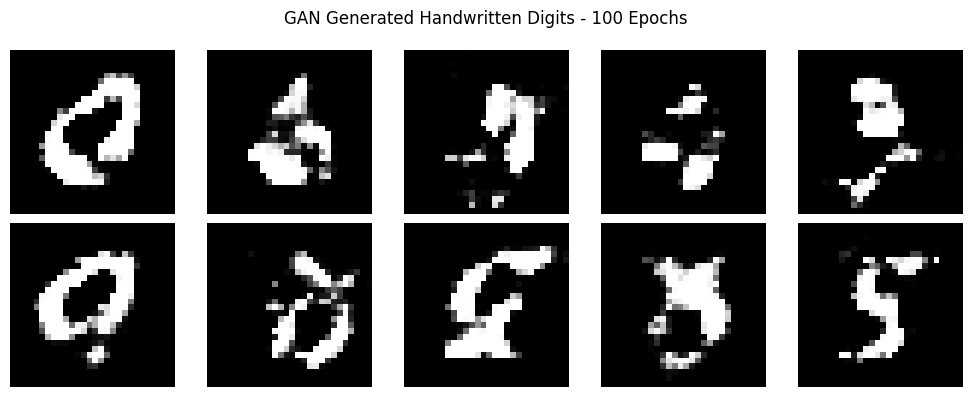

In [8]:
noise = tf.random.normal((10, 100))
generated_images = generator(noise, training=False)

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    image = (generated_images[i, :, :, 0] + 1) / 2
    plt.imshow(image, cmap="gray")
    plt.axis("off")

plt.suptitle("GAN Generated Handwritten Digits - 100 Epochs")
plt.tight_layout()
plt.show()